In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [2]:
df = pd.read_csv("salaries.csv")

In [3]:
df.head()

,years_of_experience,salary
0,5,3150
1,9,3787
2,4,2991
3,10,4551
4,8,3540


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   years_of_experience  100 non-null    int64
 1   salary               100 non-null    int64
dtypes: int64(2)
memory usage: 1.7 KB


In [5]:
# Check for missing values 
df.isnull().sum()

years_of_experience    0
salary                 0
dtype: int64

In [6]:
df.shape

(100, 2)

In [7]:
# X is independent and y is Dependent
X = df[['years_of_experience']]
y = df['salary']

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42'

In [9]:
X_train.shape, X_test.shape

((80, 1), (20, 1))

In [10]:
from sklearn.linear_model import LinearRegression

In [11]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[189.68]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['years_of_experience']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2246
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [12]:
y_pred = model.predict(X_test)

In [13]:
comparison = pd.DataFrame({'Actual salary' : y_test.values, 'Predicted salary' : y_pred})
comparison.head(10)

,Actual salary,Predicted salary
0,3483,3384.171289
1,2389,2435.756982
2,3084,3004.805566
3,2669,2625.439843
4,4553,4142.902735
5,3561,3573.854151
6,3638,3763.537012
7,2479,2435.756982
8,2781,3004.805566
9,3150,3194.488428


In [14]:
from sklearn.metrics import mean_squared_error, r2_score

In [15]:
mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error:", mse)

Mean Squared Error: 22766.874553276146


In [18]:
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

Root Mean Squared Error: 150.88695952028507


In [19]:
r2 = r2_score(y_test, y_pred)
print("R-Squared:", r2)

R-Squared: 0.9373858925288361


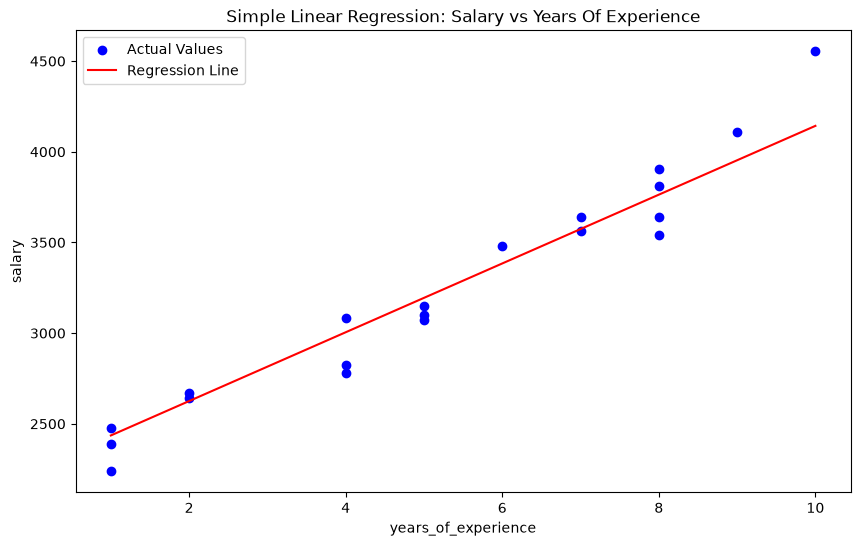

In [26]:
plot_data = pd.DataFrame({
    'years_of_experience' : X_test['years_of_experience'].values,
    'predicted_salary' : y_pred
}).sort_values('years_of_experience')

plt.figure(figsize=(10, 6))

plt.scatter(X_test['years_of_experience'], y_test,
            color='blue', label='Actual Values')

plt.plot(plot_data['years_of_experience'], plot_data['predicted_salary'],
         color='red', label='Regression Line')

plt.xlabel('years_of_experience')
plt.ylabel('salary')
plt.title('Simple Linear Regression: Salary vs Years Of Experience')

plt.legend()
plt.show()

